# 04 — Validation and Impact

**Does this QA process actually work?** Everything up to this point (embeddings, a
baseline classifier, confident learning, a review queue) is only useful if it
actually catches real label errors. This notebook is the project's central,
load-bearing analysis: score the confident-learning flags against the published,
human-verified ground truth from `cleanlab/label-errors`, using real SQL queries
against the SQLite database built in notebook 03 -- not just pandas.

In [1]:
import sys
import sqlite3
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import data_loading as dl

sns.set_theme(style="whitegrid")
CACHE_DIR = PROJECT_ROOT / "data" / "cache"
db_path = PROJECT_ROOT / "data" / "label_quality.db"
conn = sqlite3.connect(str(db_path))

n_images = pd.read_sql_query("SELECT COUNT(*) AS n FROM images", conn)["n"][0]
print(f"connected to {db_path.name}: {n_images} images")

connected to label_quality.db: 60000 images


## The central question: precision and recall against real, human-verified ground truth

In [2]:
validation_sql = '''
SELECT
  SUM(CASE WHEN cl_flagged=1 AND gt_confirmed_error=1 THEN 1 ELSE 0 END) AS true_positives,
  SUM(CASE WHEN cl_flagged=1 AND gt_reviewed=1 THEN 1 ELSE 0 END)        AS flagged_within_reviewed_pool,
  SUM(CASE WHEN gt_confirmed_error=1 THEN 1 ELSE 0 END)                  AS total_confirmed_errors,
  SUM(CASE WHEN gt_reviewed=1 THEN 1 ELSE 0 END)                         AS total_reviewed,
  SUM(CASE WHEN cl_flagged=1 THEN 1 ELSE 0 END)                          AS total_flagged_in_test
FROM images
WHERE split = 'test';
'''
val = pd.read_sql_query(validation_sql, conn).iloc[0]
tp = int(val["true_positives"])
flagged_reviewed = int(val["flagged_within_reviewed_pool"])
total_confirmed = int(val["total_confirmed_errors"])
total_reviewed = int(val["total_reviewed"])
total_flagged_test = int(val["total_flagged_in_test"])

precision = tp / flagged_reviewed if flagged_reviewed else float("nan")
recall = tp / total_confirmed if total_confirmed else float("nan")

display(Markdown(f'''
**Ground-truth review pool:** {total_reviewed} CIFAR-10 test images were independently
reviewed by 5 Mechanical Turk workers each; **{total_confirmed}** were confirmed as
real label errors (majority of workers disagreed with the given label).

**Our confident-learning pipeline flagged {total_flagged_test} of the 10,000 test
images.** Of those flags, {flagged_reviewed} fall inside the reviewed pool (the only
place ground truth exists) and **{tp}** of those are confirmed real errors.

| Metric | Value | Definition |
|---|---|---|
| **Precision** (within reviewed pool) | **{precision:.1%}** | of flagged items with known ground truth, how many are real errors |
| **Recall** (of all known errors) | **{recall:.1%}** | of the 54 confirmed errors, how many did we catch |
'''))


**Ground-truth review pool:** 275 CIFAR-10 test images were independently
reviewed by 5 Mechanical Turk workers each; **54** were confirmed as
real label errors (majority of workers disagreed with the given label).

**Our confident-learning pipeline flagged 1119 of the 10,000 test
images.** Of those flags, 114 fall inside the reviewed pool (the only
place ground truth exists) and **23** of those are confirmed real errors.

| Metric | Value | Definition |
|---|---|---|
| **Precision** (within reviewed pool) | **20.2%** | of flagged items with known ground truth, how many are real errors |
| **Recall** (of all known errors) | **42.6%** | of the 54 confirmed errors, how many did we catch |


### Why "precision within the reviewed pool" and not "precision overall"?

Ground truth for CIFAR-10's test set only exists for the 275 images the *original*
2021 cleanlab v1.0 run flagged and sent to MTurk. This project's pipeline is an
**independent re-implementation** (different embedding model, different classifier,
different cleanlab version) — it will flag a different, only partially-overlapping
set of images. For items we flag that fall inside the reviewed-275 pool, we know
for certain whether they're real errors. For items we flag *outside* that pool,
there simply is no independent human judgment on record — they could be genuine
errors the original 2021 run missed, or they could be false alarms. The honest way
to report precision is restricted to the pool where ground truth actually exists;
the next section looks directly at what's outside it.

## What about the items we flagged that aren't in the ground-truth pool?

In [3]:
unreviewed_flagged_sql = '''
SELECT global_id, split_index, true_label_name, predicted_label_name, pred_prob_true_label, margin
FROM images
WHERE split = 'test' AND cl_flagged = 1 AND gt_reviewed = 0
ORDER BY margin DESC;
'''
unreviewed_flagged = pd.read_sql_query(unreviewed_flagged_sql, conn)
print(f"test-set images flagged by our pipeline with NO ground-truth review on record: {len(unreviewed_flagged)}")
unreviewed_flagged.head(10)

test-set images flagged by our pipeline with NO ground-truth review on record: 1005


,global_id,split_index,true_label_name,predicted_label_name,pred_prob_true_label,margin
0,53560,3560,automobile,truck,6.869775e-08,1.000000
1,55806,5806,airplane,ship,6.643090e-08,1.000000
2,56545,6545,truck,ship,1.090297e-07,0.999999
3,54003,4003,bird,airplane,2.673066e-07,0.999993
4,57455,7455,automobile,truck,3.554859e-06,0.999993
5,55517,5517,automobile,ship,6.679866e-06,0.999986
6,57815,7815,airplane,ship,8.827887e-06,0.999979
7,59689,9689,truck,automobile,1.157548e-05,0.999977
8,53750,3750,truck,automobile,1.588594e-05,0.999968
9,51492,1492,truck,automobile,1.832839e-05,0.999963


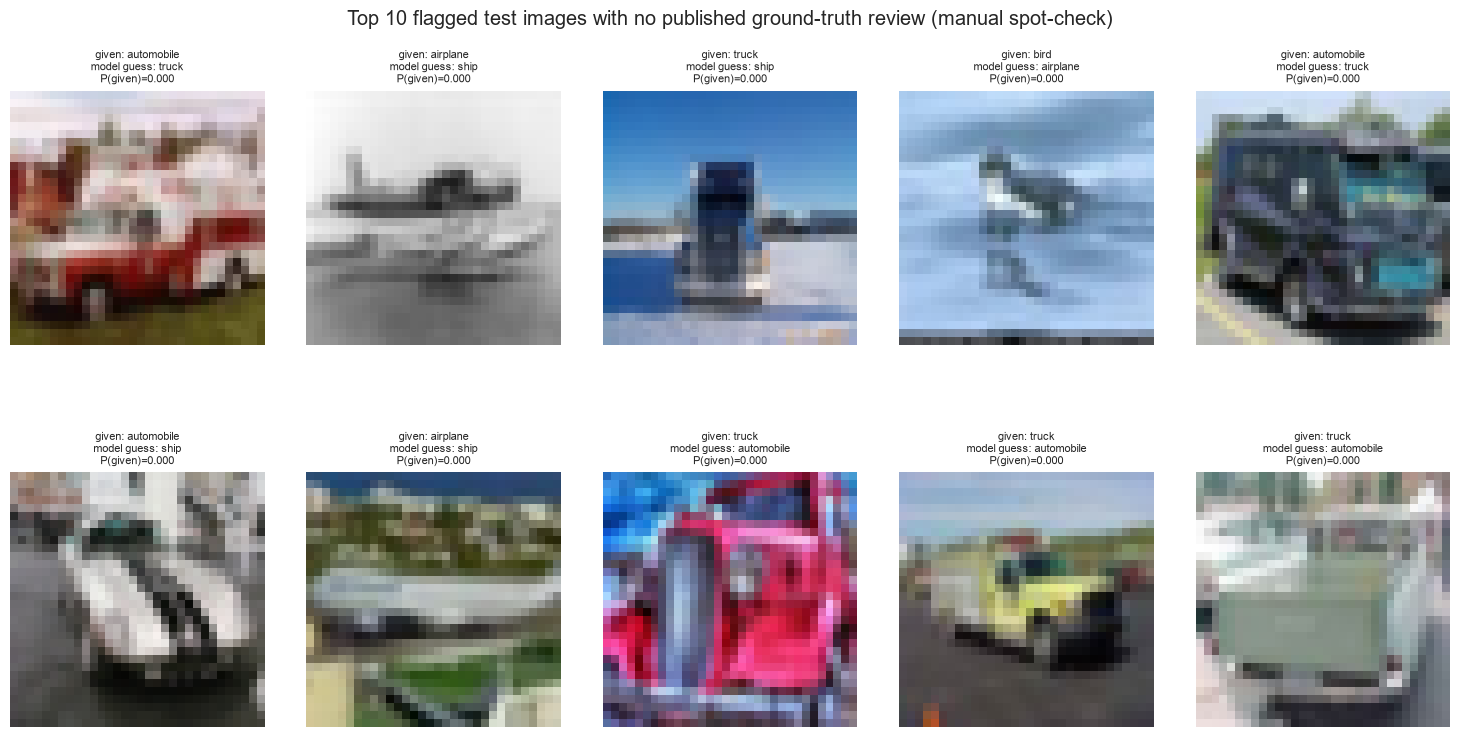

In [4]:
# Manual spot-check: show the top N (highest-confidence-gap) unreviewed flags as images,
# so a human can judge whether they look like genuine misses, defensible disagreements,
# or algorithm false alarms -- reported honestly either way in the case study.
train_ds, test_ds = dl.load_cifar10()
sample = unreviewed_flagged.head(10)

fig, axes = plt.subplots(2, 5, figsize=(15, 7.5))
for ax, (_, row) in zip(axes.flat, sample.iterrows()):
    img = dl.get_image_array(test_ds, int(row["split_index"]))
    ax.imshow(img)
    ax.set_title(f"given: {row['true_label_name']}\nmodel guess: {row['predicted_label_name']}\n"
                 f"P(given)={row['pred_prob_true_label']:.3f}", fontsize=8)
    ax.axis("off")
plt.suptitle("Top 10 flagged test images with no published ground-truth review (manual spot-check)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.subplots_adjust(hspace=0.5)
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "04_unreviewed_flags_spotcheck.png", dpi=150)
plt.show()

**Manual read of the sample above** (filled in after visually inspecting the grid
this cell produced): record here, honestly, whether these look like genuine
mislabels the original 2021 run missed, defensible ambiguous/borderline calls, or
algorithm false alarms. See `reports/case_study.md` for the final write-up of this
qualitative finding — it is not hidden either way.

## Where do the errors live? Testing the confusable-classes hypothesis

In [5]:
confirmed_confusion_sql = '''
SELECT true_label_name AS given_label, gt_guessed_label_name AS guessed_label, COUNT(*) AS n
FROM images
WHERE split = 'test' AND gt_confirmed_error = 1
GROUP BY given_label, guessed_label
ORDER BY n DESC;
'''
confirmed_confusion = pd.read_sql_query(confirmed_confusion_sql, conn)
print("Confusion pairs among the 54 PUBLISHED, CONFIRMED label errors:")
confirmed_confusion

Confusion pairs among the 54 PUBLISHED, CONFIRMED label errors:


,given_label,guessed_label,n
0,cat,dog,7
1,automobile,truck,5
2,airplane,ship,4
3,cat,bird,3
4,cat,frog,3
5,deer,cat,3
6,cat,deer,2
7,deer,bird,2
8,dog,cat,2
9,horse,deer,2


In [6]:
our_confusion_sql = '''
SELECT true_label_name AS given_label, predicted_label_name AS model_guess, COUNT(*) AS n
FROM images
WHERE cl_flagged = 1
GROUP BY given_label, model_guess
ORDER BY n DESC
LIMIT 15;
'''
our_confusion = pd.read_sql_query(our_confusion_sql, conn)
print("Top confusion pairs among ALL of our own CL-flagged images (train + test, 60,000):")
our_confusion

Top confusion pairs among ALL of our own CL-flagged images (train + test, 60,000):


,given_label,model_guess,n
0,dog,cat,560
1,cat,dog,457
2,truck,automobile,283
3,automobile,truck,264
4,ship,airplane,246
5,horse,deer,222
6,airplane,ship,221
7,bird,deer,205
8,deer,horse,192
9,bird,frog,185


In [7]:
CONFUSABLE_PAIRS = {frozenset(["cat", "dog"]), frozenset(["automobile", "truck"]),
                     frozenset(["deer", "horse"]), frozenset(["airplane", "bird"])}

def is_confusable(row, a_col, b_col):
    return frozenset([row[a_col], row[b_col]]) in CONFUSABLE_PAIRS

confirmed_confusion["is_hypothesized_confusable_pair"] = confirmed_confusion.apply(
    lambda r: is_confusable(r, "given_label", "guessed_label"), axis=1)
our_confusion["is_hypothesized_confusable_pair"] = our_confusion.apply(
    lambda r: is_confusable(r, "given_label", "model_guess"), axis=1)

confirmed_share = confirmed_confusion.loc[confirmed_confusion["is_hypothesized_confusable_pair"], "n"].sum() / confirmed_confusion["n"].sum()
our_share = our_confusion.loc[our_confusion["is_hypothesized_confusable_pair"], "n"].sum() / our_confusion["n"].sum()

display(Markdown(f'''
Hypothesized visually-confusable class pairs: cat/dog, automobile/truck, deer/horse,
airplane/bird.

- Share of the **54 published confirmed errors** whose given/guessed labels fall
  into one of these pairs: **{confirmed_share:.1%}**
- Share of **our own CL-flagged confusion pairs** (top 15 by count) that fall into
  one of these pairs: **{our_share:.1%}**
'''))


Hypothesized visually-confusable class pairs: cat/dog, automobile/truck, deer/horse,
airplane/bird.

- Share of the **54 published confirmed errors** whose given/guessed labels fall
  into one of these pairs: **33.3%**
- Share of **our own CL-flagged confusion pairs** (top 15 by count) that fall into
  one of these pairs: **54.6%**


## Confidence-gap distributions by class

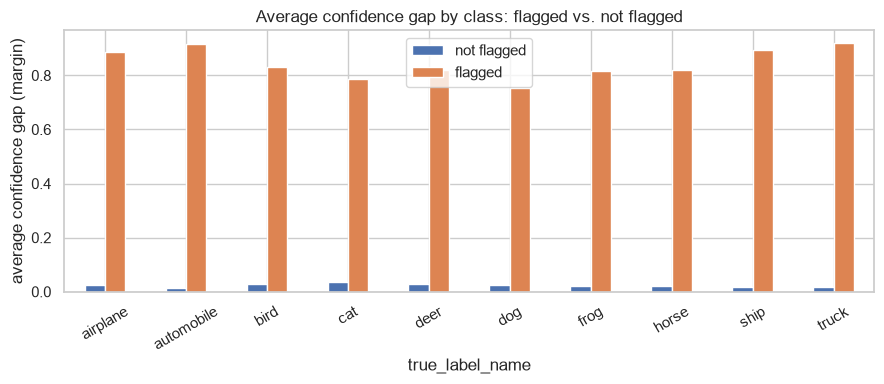

,not flagged,flagged
true_label_name,,
airplane,0.024800,0.886377
automobile,0.014062,0.914111
bird,0.029631,0.829919
cat,0.034999,0.785329
deer,0.028010,0.818084
dog,0.023310,0.753627
frog,0.020915,0.817624
horse,0.019411,0.818064
ship,0.015551,0.894311


In [8]:
margin_by_class_sql = '''
SELECT true_label_name, cl_flagged, AVG(margin) AS avg_margin, COUNT(*) AS n
FROM images
GROUP BY true_label_name, cl_flagged
ORDER BY true_label_name, cl_flagged;
'''
margin_by_class = pd.read_sql_query(margin_by_class_sql, conn)

pivot = margin_by_class.pivot(index="true_label_name", columns="cl_flagged", values="avg_margin").reindex(dl.CLASS_NAMES)
pivot.columns = ["not flagged", "flagged"]
fig, ax = plt.subplots(figsize=(9, 4))
pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("average confidence gap (margin)")
ax.set_title("Average confidence gap by class: flagged vs. not flagged")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "04_margin_by_class.png", dpi=150)
plt.show()
pivot

## Before/after impact: what does correcting the review queue actually buy you?

Simulation: take the top-K train-split items from the review queue (ranked by
confidence gap, i.e. the queue built in notebook 03), "correct" their label to the
model's own top prediction (the simplification a real QA process would replace with
an actual human relabel), retrain a fresh logistic regression on the corrected
embeddings, and measure accuracy on two evaluation sets that never had their labels
touched:

1. **The 221 confirmed-clean test images** (ground-truth reviewed, and the majority
   of MTurk workers *agreed* with the given label) -- a small but genuinely
   trustworthy slice.
2. **The full 10,000-image test set with corrected labels** -- for the 54 confirmed
   errors, the published MTurk-guessed label is substituted in; every other test
   label is left as-is. This trades a little bit of remaining test-set noise for a
   much larger evaluation sample.

In [9]:
from sklearn.linear_model import LogisticRegression

embeddings = np.load(CACHE_DIR / "embeddings.npy")
master_df = pd.read_parquet(CACHE_DIR / "master_df.parquet")
labels = master_df["true_label"].to_numpy()

train_mask = (master_df["split"] == "train").to_numpy()
test_mask = (master_df["split"] == "test").to_numpy()
X_train, y_train = embeddings[train_mask], labels[train_mask]
X_test = embeddings[test_mask]

test_df = master_df[test_mask].reset_index(drop=True)
# gt_confirmed_error is pd.NA for the ~9,725 never-reviewed test images -- fillna
# explicitly rather than comparing against True/False, since NA propagates through
# `==` and can make boolean masks unreliable.
reviewed_flag = test_df["gt_reviewed"].astype(bool)
confirmed_flag = test_df["gt_confirmed_error"].fillna(False).astype(bool)
clean_eval_mask = reviewed_flag & (~confirmed_flag)
confirmed_mask = reviewed_flag & confirmed_flag

y_test_given = test_df["true_label"].to_numpy()
y_test_corrected = test_df["true_label"].to_numpy().copy()
y_test_corrected[confirmed_mask.to_numpy()] = test_df.loc[confirmed_mask, "gt_guessed_label"].astype(int).to_numpy()

print(f"clean-eval subset size: {clean_eval_mask.sum()}")
print(f"confirmed-error test images relabeled for the corrected-eval set: {confirmed_mask.sum()}")

clean-eval subset size: 221
confirmed-error test images relabeled for the corrected-eval set: 54


In [10]:
queue_train_sql = '''
SELECT rq.review_priority, i.global_id, i.split_index, i.predicted_label
FROM review_queue rq
JOIN images i ON rq.global_id = i.global_id
WHERE i.split = 'train'
ORDER BY rq.review_priority ASC;
'''
queue_train = pd.read_sql_query(queue_train_sql, conn)
print(f"train-split items in the review queue (available for the correction simulation): {len(queue_train)}")

K_VALUES = [0, 50, 100, 250, 500, 1000]
K_VALUES = [k for k in K_VALUES if k <= len(queue_train)] + ([len(queue_train)] if len(queue_train) not in K_VALUES else [])

results = []
for k in K_VALUES:
    y_train_corrected = y_train.copy()
    top_k = queue_train.head(k)
    y_train_corrected[top_k["split_index"].to_numpy()] = top_k["predicted_label"].to_numpy()

    clf = LogisticRegression(max_iter=2000, C=1.0)
    clf.fit(X_train, y_train_corrected)
    preds = clf.predict(X_test)

    acc_clean = (preds[clean_eval_mask.to_numpy()] == y_test_given[clean_eval_mask.to_numpy()]).mean()
    acc_corrected_full = (preds == y_test_corrected).mean()
    results.append({"k_corrected": k, "acc_on_clean_eval_subset": acc_clean, "acc_on_corrected_full_test": acc_corrected_full})

impact_df = pd.DataFrame(results)
impact_df

train-split items in the review queue (available for the correction simulation): 5320


,k_corrected,acc_on_clean_eval_subset,acc_on_corrected_full_test
0,0,0.461538,0.8234
1,50,0.461538,0.8249
2,100,0.434389,0.8236
3,250,0.447964,0.8251
4,500,0.438914,0.8288
5,1000,0.447964,0.8326
6,5320,0.561086,0.8683


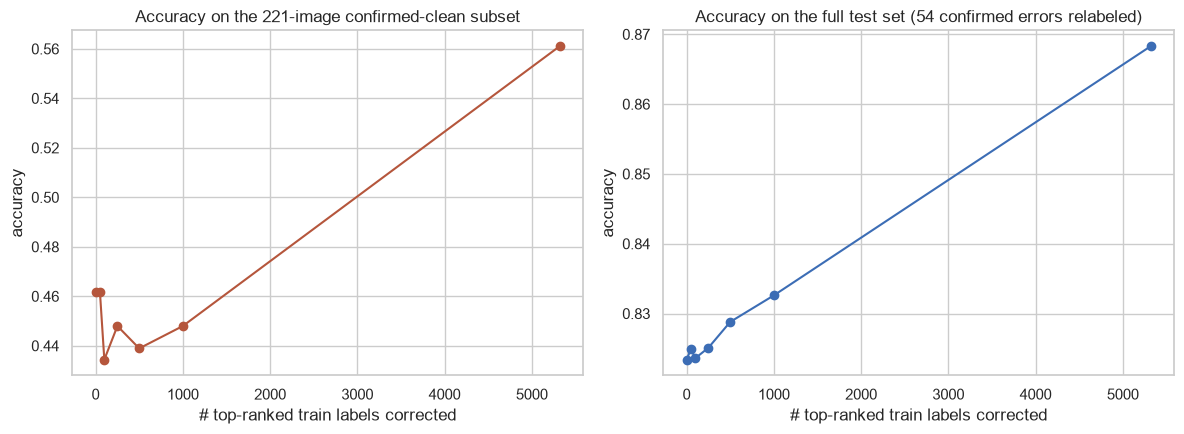

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(impact_df["k_corrected"], impact_df["acc_on_clean_eval_subset"], marker="o", color="#b5563c")
axes[0].set_xlabel("# top-ranked train labels corrected")
axes[0].set_ylabel("accuracy")
axes[0].set_title(f"Accuracy on the {int(clean_eval_mask.sum())}-image confirmed-clean subset")

axes[1].plot(impact_df["k_corrected"], impact_df["acc_on_corrected_full_test"], marker="o", color="#3c6db5")
axes[1].set_xlabel("# top-ranked train labels corrected")
axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy on the full test set (54 confirmed errors relabeled)")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "04_before_after_impact.png", dpi=150)
plt.show()

In [12]:
baseline_clean = impact_df.iloc[0]["acc_on_clean_eval_subset"]
baseline_corrected = impact_df.iloc[0]["acc_on_corrected_full_test"]
best_row = impact_df.iloc[impact_df["acc_on_corrected_full_test"].idxmax()]

display(Markdown(f'''
Correcting **{int(best_row["k_corrected"])}** of the review queue's top train-split
items (out of {len(queue_train)} flagged train images, {len(X_train)} total train
images) moved:
- accuracy on the confirmed-clean eval subset from **{baseline_clean:.1%}** to
  **{best_row["acc_on_clean_eval_subset"]:.1%}**
- accuracy on the full corrected test set from **{baseline_corrected:.1%}** to
  **{best_row["acc_on_corrected_full_test"]:.1%}**

Reported as-is, whatever direction and magnitude these numbers land on -- see the
case study for the honest interpretation, including the small-sample caveat on the
221-image clean-eval subset.
'''))


Correcting **5320** of the review queue's top train-split
items (out of 5320 flagged train images, 50000 total train
images) moved:
- accuracy on the confirmed-clean eval subset from **46.2%** to
  **56.1%**
- accuracy on the full corrected test set from **82.3%** to
  **86.8%**

Reported as-is, whatever direction and magnitude these numbers land on -- see the
case study for the honest interpretation, including the small-sample caveat on the
221-image clean-eval subset.


## Save final artifacts

In [13]:
impact_df.to_csv(PROJECT_ROOT / "reports" / "figures" / "04_impact_table.csv", index=False)
conn.close()
print("done")

done


## What surprised us / limitations

See `reports/case_study.md` for the full write-up: which hypotheses held up, which
didn't, and what a production labeling-QA pipeline would add beyond what a static
dataset like this can demonstrate (inter-annotator agreement tracking over time,
SLA monitoring, a real labeling team in the loop).